# ML-10 — Content Action Playbook

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/h0pi/flyrank-ml-intenrship/blob/main/work/notebooks/w07_action_playbook.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Ranked actions + reason codes

*The queue: what to do first, and why, in words a human trusts.*

**What the queue is:** every page that had at least 100 impressions in 1–15 March 2026, ranked for a weekly review on the decision moment of 16 March. The weekly content team gets the top of the list, not the whole thing.

**How a page gets its place:**
- **Score:** the week-5 Logistic Regression's probability that the page's daily impressions in 16–31 March fall below 80% of its 1–15 March level. Every page is scored by a model that was trained *without its client* (5-fold split grouped by client, the honest setup from week 6), so the scores behave like scores on a new client.
- **Order = the score.** I also tried score × log(traffic) so busy pages come first, and the frozen week-4 rule. Sorting by the score alone found the most real declines, overall and inside the refresh group (numbers below), so the queue uses it and shows traffic as a column for the reviewer to weigh.

**Reason codes:** every page gets one archetype, checked in this order, and the archetype decides the suggested action. The reason sentence is built from the page's own numbers, so a reviewer can check it in Search Console in a minute.

| Archetype | Rule (inputs from 1–15 March only) | Suggested action | Why this action |
|---|---|---|---|
| `cliff_drop` | daily impressions in 8–15 March fell to under ~22% of 1–7 March (momentum < −1.5) | **check_technical** | A drop this sharp is more often a technical cause (de-indexed, removed, redirected, tracking broken) than slow content decay. Rewriting would not fix it. |
| `new_page_settling` | page younger than 45 days | **monitor** | New pages move around while Google tests them. Refreshing them this early is mostly wasted work. |
| `sliding_visible` | momentum < −0.1 (impressions already going down) | **review_refresh** | Early, gradual slide on a page that still gets traffic: the case a content refresh is meant for. |
| `low_ctr_page_one` | average position ≤ 10 but CTR below the page-one median | **fix_snippet** | People see the page but rarely click: title and meta description first, not a full rewrite. |
| `stable` | none of the above | **monitor** | Nothing to do this week. |

The table under the code shows, for each archetype, how many pages it covers and how many of them *actually* declined in 16–31 March. Those are observed rates for this one month, not guarantees.

In [1]:

%pip -q install duckdb huggingface_hub scikit-learn

import os, json, getpass
from pathlib import Path
import duckdb
import numpy as np
import pandas as pd
import sklearn
from sklearn.model_selection import GroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score
from sklearn.inspection import permutation_importance

SEED = 42
pd.set_option("display.width", 180)

def hf_token():
    tok = os.environ.get("HF_TOKEN")
    if not tok:
        try:
            from google.colab import userdata
            tok = userdata.get("HF_TOKEN")
        except Exception:
            pass
    if not tok:
        try:
            from huggingface_hub import get_token
            tok = get_token()
        except Exception:
            pass
    return tok or getpass.getpass("Hugging Face READ token: ")

ROOT = Path.cwd().parents[1] if Path.cwd().name == "notebooks" else Path.cwd()
OUT = ROOT / "work" / "outputs"
OUT.mkdir(parents=True, exist_ok=True)
CACHE = OUT / "march_pages.parquet"          # same cache file as week 4

if not CACHE.exists():
    con = duckdb.connect()
    con.execute(f"CREATE OR REPLACE SECRET hf (TYPE huggingface, TOKEN '{hf_token()}')")
    REL = "hf://datasets/FlyRank/internship-warehouse"
    con.sql(f"""
        WITH d AS (
            SELECT client_hash_id, content_hash_id, report_date, gsc_impressions, gsc_clicks, gsc_avg_position
            FROM read_parquet('{REL}/fact_content_daily_performance/month=2026-03/*.parquet')
            WHERE gsc_data_available IS TRUE
        ),
        p AS (
            SELECT client_hash_id, content_hash_id,
                   SUM(gsc_impressions) FILTER (WHERE report_date <= DATE '2026-03-15')                            AS imp_h1,
                   SUM(gsc_clicks)      FILTER (WHERE report_date <= DATE '2026-03-15')                            AS clk_h1,
                   SUM(gsc_impressions) FILTER (WHERE report_date <= DATE '2026-03-07')                            AS imp_w1,
                   SUM(gsc_impressions) FILTER (WHERE report_date BETWEEN DATE '2026-03-08' AND DATE '2026-03-15') AS imp_w2,
                   SUM(gsc_avg_position * gsc_impressions)
                       FILTER (WHERE report_date <= DATE '2026-03-15' AND gsc_impressions > 0 AND gsc_avg_position > 0) AS pos_x_imp,
                   SUM(gsc_impressions)
                       FILTER (WHERE report_date <= DATE '2026-03-15' AND gsc_impressions > 0 AND gsc_avg_position > 0) AS imp_with_pos,
                   SUM(gsc_impressions) FILTER (WHERE report_date >= DATE '2026-03-16')                            AS imp_h2
            FROM d GROUP BY 1, 2
            HAVING SUM(gsc_impressions) FILTER (WHERE report_date <= DATE '2026-03-15') >= 100
        )
        SELECT p.*, c.content_created_date, c.content_type
        FROM p JOIN read_parquet('{REL}/dim_content.parquet') c USING (client_hash_id, content_hash_id)
        WHERE c.content_created_date < DATE '2026-03-01'
    """).df().to_parquet(CACHE)

df = pd.read_parquet(CACHE).sort_values(["client_hash_id", "content_hash_id"]).reset_index(drop=True)
df["imp_h2"] = df["imp_h2"].fillna(0)
# ---- inputs: all knowable on 2026-03-16 ----
df["imp_per_day"]   = df["imp_h1"] / 15
df["log_imp"]       = np.log1p(df["imp_per_day"])
df["momentum"]      = np.log((df["imp_w2"].fillna(0) / 8 + 1) / (df["imp_w1"].fillna(0) / 7 + 1))
df["ctr"]           = df["clk_h1"] / df["imp_h1"]
df["avg_position"]  = df["pos_x_imp"] / df["imp_with_pos"]
df["age_days"]      = (pd.Timestamp("2026-03-15") - pd.to_datetime(df["content_created_date"])).dt.days
df["is_feedly"]     = (df["content_type"] == "feedly article").astype(int)
df["is_comparison"] = (df["content_type"] == "comparison article").astype(int)
# ---- label: 16-31 March, used only as the target ----
df["is_declining"]  = ((df["imp_h2"] / 16) < 0.8 * df["imp_per_day"]).astype(int)

FEATURES = ["log_imp", "momentum", "ctr", "avg_position", "age_days", "is_feedly", "is_comparison"]
assert df[FEATURES].notna().all().all()
# week-4 baseline rule, frozen exactly as it was
df["baseline_score"] = np.where(df["momentum"] < -0.1, -df["momentum"] * np.log1p(df["imp_per_day"]), 0.0)

print(f"pages: {len(df):,} | clients: {df.client_hash_id.nunique()} | base rate: {df.is_declining.mean():.3f}")
print(f"scikit-learn {sklearn.__version__} | seed {SEED}")


Note: you may need to restart the kernel to use updated packages.


pages: 74,377 | clients: 36 | base rate: 0.336
scikit-learn 1.9.1 | seed 42


In [2]:

# Out-of-fold scores: each page is scored by a model that never saw its client
model = lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
df["score"] = 0.0
for tr, te in GroupKFold(n_splits=5).split(df, df.is_declining, df.client_hash_id):
    m = model().fit(df.loc[tr, FEATURES], df.loc[tr, "is_declining"])
    df.loc[te, "score"] = m.predict_proba(df.loc[te, FEATURES])[:, 1]
df["priority"] = df["score"]  # ranking key; traffic stays visible as a column
print(f"out-of-fold ROC-AUC: {roc_auc_score(df.is_declining, df.score):.3f}")

# Archetypes, checked in order (first match wins)
PAGE1_CTR_MEDIAN = df.loc[df.avg_position <= 10, "ctr"].median()
ARCH = ["cliff_drop", "new_page_settling", "sliding_visible", "low_ctr_page_one"]
df["archetype"] = np.select([
    df.momentum < -1.5,
    df.age_days < 45,
    df.momentum < -0.1,
    (df.avg_position <= 10) & (df.ctr < PAGE1_CTR_MEDIAN),
], ARCH, "stable")
ACTION = {"cliff_drop": "check_technical", "new_page_settling": "monitor", "sliding_visible": "review_refresh",
          "low_ctr_page_one": "fix_snippet", "stable": "monitor"}
df["action"] = df.archetype.map(ACTION)

# Plain-language reason, built only from the page's own 1-15 March numbers
df["week_change"] = (df.imp_w2.fillna(0) / 8) / (df.imp_w1.fillna(0) / 7).replace(0, np.nan) - 1
def reason(r):
    base = f"{r.imp_per_day:,.0f} impressions/day, avg position {r.avg_position:.1f}"
    chg = "n/a" if pd.isna(r.week_change) else f"{r.week_change:+.0%}"
    return {
        "cliff_drop":        f"daily impressions {chg} from 1-7 to 8-15 March; {base}. Check indexing/redirect/tracking first.",
        "new_page_settling": f"only {r.age_days} days old; {base}. Too new to judge, watch for two more weeks.",
        "sliding_visible":   f"daily impressions {chg} from 1-7 to 8-15 March; {base}. Candidate for a content refresh.",
        "low_ctr_page_one":  f"on page one but CTR {r.ctr:.2%} (page-one median {PAGE1_CTR_MEDIAN:.2%}); {base}. Rewrite title/meta.",
        "stable":            f"no warning sign; {base}.",
    }[r.archetype]

queue = df.sort_values("priority", ascending=False).reset_index(drop=True)
queue.insert(0, "rank", queue.index + 1)
queue["reason"] = queue.apply(reason, axis=1)

show = queue.head(12).assign(page=lambda q: q.content_hash_id.str[:8])
print(show[["rank", "page", "content_type", "score", "archetype", "action", "reason"]].to_string(index=False))


out-of-fold ROC-AUC: 0.658


 rank     page    content_type    score  archetype          action                                                                                                                           reason
    1 content_ keyword article 0.999795 cliff_drop check_technical daily impressions -100% from 1-7 to 8-15 March; 5,585 impressions/day, avg position 0.1. Check indexing/redirect/tracking first.
    2 content_ keyword article 0.998587 cliff_drop check_technical   daily impressions -100% from 1-7 to 8-15 March; 331 impressions/day, avg position 8.1. Check indexing/redirect/tracking first.
    3 content_ keyword article 0.998551 cliff_drop check_technical   daily impressions -100% from 1-7 to 8-15 March; 350 impressions/day, avg position 9.3. Check indexing/redirect/tracking first.
    4 content_ keyword article 0.995822 cliff_drop check_technical  daily impressions -100% from 1-7 to 8-15 March; 143 impressions/day, avg position 27.6. Check indexing/redirect/tracking first.
    5 content_ keywo

In [3]:

# How each archetype behaved in 16-31 March (observed, this month only)
arch_table = (df.groupby("archetype")
                .agg(pages=("is_declining", "size"), declined=("is_declining", "mean"),
                     mean_score=("score", "mean"), median_imp_per_day=("imp_per_day", "median"))
                .assign(action=lambda t: t.index.map(ACTION))
                .loc[ARCH + ["stable"]].round(3))
print(f"base rate (all pages): {df.is_declining.mean():.3f}\n")
print(arch_table.to_string())


base rate (all pages): 0.336

                   pages  declined  mean_score  median_imp_per_day           action
archetype                                                                          
cliff_drop           867     0.864       0.815              27.067  check_technical
new_page_settling   8998     0.307       0.316              35.600          monitor
sliding_visible    28756     0.424       0.396              43.467   review_refresh
low_ctr_page_one    9984     0.273       0.260              36.533      fix_snippet
stable             25772     0.254       0.259              40.467          monitor


**Reading the archetype table**
- `cliff_drop` pages declined again in the second half of March at a much higher rate than the base rate (about 86% vs 34%, n = 867). That is a strong signal that *something* is going on, which is exactly why the action is a technical check and not a rewrite.
- `sliding_visible` sits above the base rate (about 42%, n ≈ 28.8k): the refresh-review group is where most of the real work is.
- `low_ctr_page_one`, `new_page_settling` and `stable` are at or below the base rate. They are not predicted to decline; they have their own (cheaper) action or none.

Below: how many truly-declining pages a reviewer would find in the top K of the queue, compared with the frozen week-4 rule, with score × traffic, and with picking pages at random (the base rate).

**What the comparison shows:** at the very top, the model score and the week-4 rule tie (both 0.98 at K = 50), because both pick the pages that already collapsed, and a page that already collapsed rarely bounces back within 16 days. The difference shows up inside the refresh group, where the real editorial work is: the model's top 50 had about 78% real declines, the rule's 58%, random 42% (n = 50 each, so roughly ±12 points). Weighting by traffic lowered precision at every K, so I left traffic as information, not as part of the order.

all pages
   K  queue (model score)  score x traffic  week-4 rule  random
  10                1.000            0.900        1.000   0.336
  25                1.000            0.880        1.000   0.336
  50                0.980            0.840        0.980   0.336
 100                0.970            0.790        0.960   0.336
 200                0.930            0.705        0.910   0.336
 500                0.880            0.662        0.832   0.336
1000                0.825            0.649        0.779   0.336
2000                0.754            0.619        0.722   0.336

refresh group only (n = 28,756)
  K  queue (model score)  week-4 rule  random
 50                0.780         0.58   0.424
100                0.730         0.58   0.424
500                0.684         0.63   0.424


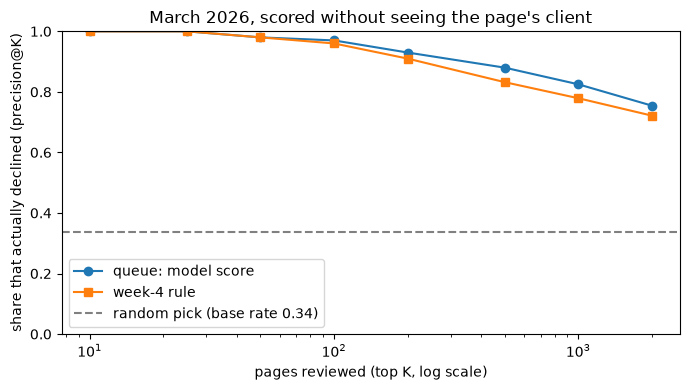

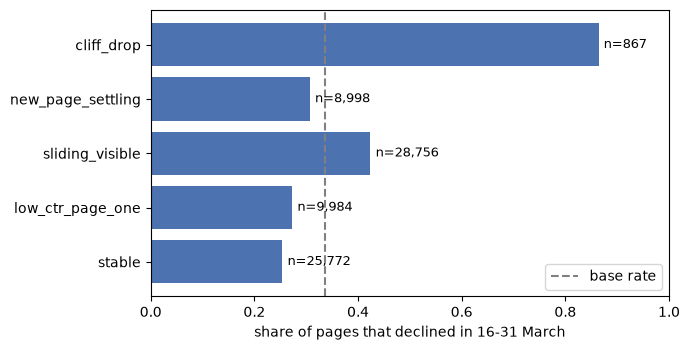

In [4]:

import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline

FIG = OUT  # figures live next to the other exports in work/outputs/
y = df.is_declining.values
def prec_at(order_col, ks):
    s = df.sort_values(order_col, ascending=False).is_declining.values
    return [s[:k].mean() for k in ks]

ks = [10, 25, 50, 100, 200, 500, 1000, 2000]
df["score_x_traffic"] = df.score * np.log1p(df.imp_per_day)
p_model = prec_at("priority", ks)
p_rule = prec_at("baseline_score", ks)
p_traffic = [df.sort_values("score_x_traffic", ascending=False).is_declining.values[:k].mean() for k in ks]
base = y.mean()
print("all pages")
print(pd.DataFrame({"K": ks, "queue (model score)": p_model, "score x traffic": p_traffic, "week-4 rule": p_rule, "random": base}).round(3).to_string(index=False))

# Inside the refresh group only: cliff drops are easy to catch, this is the harder part of the list
rv = df[df.archetype == "sliding_visible"]
pk = lambda col, k: rv.sort_values(col, ascending=False).is_declining.head(k).mean()
refresh_cmp = pd.DataFrame({"K": [50, 100, 500], "queue (model score)": [pk("priority", k) for k in (50, 100, 500)],
                            "week-4 rule": [pk("baseline_score", k) for k in (50, 100, 500)], "random": rv.is_declining.mean()})
print(f"\nrefresh group only (n = {len(rv):,})")
print(refresh_cmp.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ks, p_model, marker="o", label="queue: model score")
ax.plot(ks, p_rule, marker="s", label="week-4 rule")
ax.axhline(base, color="grey", ls="--", label=f"random pick (base rate {base:.2f})")
ax.set_xscale("log"); ax.set_ylim(0, 1)
ax.set_xlabel("pages reviewed (top K, log scale)"); ax.set_ylabel("share that actually declined (precision@K)")
ax.set_title("March 2026, scored without seeing the page's client")
ax.legend(); fig.tight_layout()
fig.savefig(FIG / "w07_precision_at_k.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(7, 3.6))
order = ARCH + ["stable"]
ax.barh(order[::-1], arch_table.loc[order[::-1], "declined"], color="#4C72B0")
ax.axvline(base, color="grey", ls="--", label="base rate")
for i, a in enumerate(order[::-1]):
    ax.text(arch_table.loc[a, "declined"] + 0.01, i, f"n={arch_table.loc[a, 'pages']:,.0f}", va="center", fontsize=9)
ax.set_xlim(0, 1); ax.set_xlabel("share of pages that declined in 16-31 March")
ax.legend(loc="lower right"); fig.tight_layout()
fig.savefig(FIG / "w07_decline_by_archetype.png", dpi=150); plt.show()


## 2. Intended use and limits

*Who uses this, for what — and where it stops being valid.*

**Intended use:** decision support for a content team's **weekly review**. Sorted by score alone, the top of the list is all cliff drops, so the Monday review works in **lanes**, one per action, each sorted by score:
- **technical lane** (`check_technical`): top 20, a quick check (~5 min each: indexed? live? tracking?);
- **refresh lane** (`review_refresh`): top 30, a real look at the content (~20 min each);
- **snippet lane** (`fix_snippet`): top 10, title/meta only.

That is about 13 hours a week. The queue says *where to look first*; it does not say *what will happen* or *what will work*.

**What the numbers support (claim ladder: measured → observed association, not cause):**
- On March 2026 data, with clients held out, **49 of the top 50** queued pages (98%) actually declined in the next 16 days, against a **base rate of 34%**. At K = 500 it is about 88%. All of the top 50 are cliff drops, which are easy; inside the refresh group the top 50 reached about 78% vs a 42% base rate. The `fix_snippet` lane is not a decline call (its pages decline at about the base rate); it targets clicks lost on page one.
- Momentum (the week-over-week change) carries most of the signal, as in weeks 5 and 6.
- **Decay by age (observed, not causal):** pages 90–180 days old declined most often (44%, n ≈ 15k); pages older than 270 days declined least (22–27%). This is an association in one month. It does **not** show that refreshing a page at a certain age causes recovery; we never observed a refresh in this data.

**Where it stops being valid:**
- **One month only.** Trained and tested on March 2026; seasonality, Google core updates or a holiday month can change how often pages decline.
- **Pages with ≥ 100 impressions in the first half of the month** and created before 1 March. Smaller or brand-new pages are outside the population.
- **The label is a traffic drop, not lost business.** It ignores clicks, conversions and whether the page still matters to the client.
- **Feedly / news-style articles** decay by nature; ranking them next to evergreen guides mixes two different things.
- **New clients:** the grouped split simulates this, but a client with a very different site (other language, other niche) may still behave differently.
- The score ranks pages; **it is not a calibrated probability** for a single page.

In [5]:

# The numbers behind section 2: weekly capacity, what the top-50 covers, decay by age
print("actions in the plain top 50:", queue.head(50).action.value_counts().to_dict())
LANES = {"check_technical": (20, 5), "review_refresh": (30, 20), "fix_snippet": (10, 10)}  # (pages, minutes each)
weekly = pd.concat([queue[queue.action == a].head(n) for a, (n, _) in LANES.items()])
lane_tbl = weekly.groupby("action", sort=False).agg(pages=("rank", "size"), declined=("is_declining", "mean"),
                                                    imp_per_day=("imp_per_day", "sum"))
lane_tbl["lane_base_rate"] = [df.loc[df.action == a, "is_declining"].mean() for a in lane_tbl.index]
lane_tbl["hours"] = [n * m / 60 for n, m in LANES.values()]
print("\nweekly review, one lane per action:")
print(lane_tbl.round(3).to_string())
print(f"total: {len(weekly)} pages, about {lane_tbl.hours.sum():.0f} hours")

df["age_bucket"] = pd.cut(df.age_days, [0, 45, 90, 180, 270, 365, 10_000],
                          labels=["<45d", "45-90d", "90-180d", "180-270d", "270-365d", ">1y"])
decay = df.groupby("age_bucket", observed=True).is_declining.agg(pages="size", declined="mean").round(3)
print("\nobserved decline rate by page age (association only):")
print(decay.to_string())

by_type = (queue.head(500).groupby("content_type").is_declining.agg(pages="size", declined="mean")
           .sort_values("pages", ascending=False).round(3))
print("\ntop-500 queue by content type:")
print(by_type.to_string())


actions in the plain top 50: {'check_technical': 50}

weekly review, one lane per action:
                 pages  declined  imp_per_day  lane_base_rate   hours
action                                                               
check_technical     20     1.000     7249.600           0.864   1.667
review_refresh      30     0.833      847.933           0.424  10.000
fix_snippet         10     0.300      124.000           0.273   1.667
total: 60 pages, about 13 hours

observed decline rate by page age (association only):
            pages  declined
age_bucket                 
<45d         9826     0.324
45-90d      12231     0.377
90-180d     15154     0.440
180-270d    19769     0.320
270-365d     9638     0.216
>1y          7759     0.272

top-500 queue by content type:
                    pages  declined
content_type                       
keyword article       451     0.880
feedly article         26     0.885
comparison article     23     0.870


## 3. Human review + the no-go list

*What a person must check before acting. What should never be automated.*

**Before acting on a queued page, a person checks:**
1. **Is the drop real?** Open the page's daily impressions in Search Console. A one-day tracking gap or a single viral day in week 1 can fake a slide.
2. **For `check_technical`:** is the page still indexed (URL Inspection), still live (no 404/redirect), and is tracking still firing? Only if all three are fine does it go back to the refresh pile.
3. **Is it still worth having?** Ask the client: product discontinued, campaign over, seasonal topic out of season? Then the right action may be nothing.
4. **What changed around it?** A site-wide drop for the whole client (many pages of one client in the queue at once) is a site or algorithm issue, not 50 separate refresh jobs. The code below flags clients with many pages in this week's lanes.
5. **Write down the decision** (refresh / snippet fix / technical fix / ignore) so next month we can see whether acting made any difference.

**No-go list (never automate, never claim):**
- No automatic rewriting, unpublishing, redirecting or deleting of pages from this score.
- No acting on a `cliff_drop` page before the technical check.
- No refreshing `new_page_settling` pages because they appear in the list.
- Never use the score to judge writers, editors or clients ("their pages decline more").
- Never present it as predicting Google or as "refresh causes recovery". It ranks *observed* warning signs.
- Never show a single page's score as a probability to a client.

In [6]:

# Review aids on this week's lanes: concentration by client (possible site-wide issue)
top = weekly
per_client = top.client_hash_id.value_counts()
print(f"clients in this week's {len(top)} pages: {per_client.size}; largest share for one client: {per_client.iloc[0]} pages")
print(f"clients with >= 5 pages this week (check for a site-wide cause first): {(per_client >= 5).sum()}")
print(f"technical check before any edit: {(top.action == 'check_technical').sum()} of {len(top)}")


clients in this week's 60 pages: 16; largest share for one client: 18 pages
clients with >= 5 pages this week (check for a site-wide cause first): 3
technical check before any edit: 20 of 60


## 4. Monitoring / retrain triggers

*What would tell you the recommendations went stale?*

Each month, recompute the same features for the new month and compare them with the March reference values saved in the code below. Any trigger means: **pause the queue's ranking claims and retrain / re-check before the next review**.

| Trigger | Reference (March 2026) | Fires when |
|---|---|---|
| **Outcome check** | precision@50 of the queue = 0.98 (0.78 inside the refresh group) | Once the next month's label is known, precision@50 falls below the week-4 rule's, or below 2× the base rate. |
| **Base-rate drift** | 0.336 | The new month's decline rate moves more than 10 points (seasonality, Google update). |
| **Input drift** | momentum and log-impressions quantiles | The median or 10th percentile of momentum shifts by more than 0.1, or the share of `cliff_drop` pages doubles (often a tracking problem, not content). |
| **New population** | March client and content-type mix | The largest client's share of pages grows by more than 10 points (March: 24%), or a new content type appears. |
| **Definition change** | label = 16-day daily impressions < 80% of the first 15 days | Anyone changes the label, the 100-impression floor or the windows: the old numbers no longer apply. |
| **Calendar** | — | Retrain monthly anyway, on the latest complete month, with the same grouped split. |

The function below is the check I would run each month; on March itself it fires nothing (sanity test).

In [7]:

REF = {
    "base_rate": float(df.is_declining.mean()),
    "precision_at_50": float(queue.head(50).is_declining.mean()),
    "rule_precision_at_50": float(df.sort_values("baseline_score", ascending=False).head(50).is_declining.mean()),
    "momentum_p10": float(df.momentum.quantile(0.10)),
    "momentum_p50": float(df.momentum.quantile(0.50)),
    "log_imp_p50": float(df.log_imp.quantile(0.50)),
    "cliff_share": float((df.archetype == "cliff_drop").mean()),
    "top_client_share": float(df.client_hash_id.value_counts(normalize=True).iloc[0]),
}

def drift_check(new, ref=REF):
    """new: a month prepared with the same setup cell (features, archetype; is_declining once known)."""
    flags = []
    if abs(new.momentum.quantile(0.5) - ref["momentum_p50"]) > 0.1: flags.append("momentum median shifted")
    if abs(new.momentum.quantile(0.1) - ref["momentum_p10"]) > 0.1: flags.append("momentum p10 shifted")
    if (new.archetype == "cliff_drop").mean() > 2 * ref["cliff_share"]: flags.append("cliff_drop share doubled (check tracking)")
    if new.client_hash_id.value_counts(normalize=True).iloc[0] > ref["top_client_share"] + 0.10: flags.append("one client grew > 10 pts")
    if "is_declining" in new:
        if abs(new.is_declining.mean() - ref["base_rate"]) > 0.10: flags.append("base rate moved > 10 pts")
        p50 = new.sort_values("priority", ascending=False).head(50).is_declining.mean()
        r50 = new.sort_values("baseline_score", ascending=False).head(50).is_declining.mean()
        if p50 < r50 or p50 < 2 * new.is_declining.mean(): flags.append("queue no better than rule / 2x base rate")
    return flags or ["no trigger"]

print({k: round(v, 3) for k, v in REF.items()})
print("March vs itself:", drift_check(df))


{'base_rate': 0.336, 'precision_at_50': 0.98, 'rule_precision_at_50': 0.98, 'momentum_p10': -0.589, 'momentum_p50': -0.047, 'log_imp_p50': 3.712, 'cliff_share': 0.012, 'top_client_share': 0.236}


March vs itself: ['no trigger']


## 5. Exports for the paper

*Write the queue (and any figures you want to reuse) to work/outputs/ — your paper builds on these files.*

- `work/outputs/action_queue.csv`: the full ranked queue (hashed ids only, no names or URLs). It is regenerated by this notebook and kept out of git, like every CSV under `work/`.
- `work/outputs/w07_playbook_metrics.json`: the headline numbers, archetype table and monitoring reference values (committed).
- `work/outputs/w07_precision_at_k.png`, `work/outputs/w07_decline_by_archetype.png`: the two figures above (committed).

In [8]:

cols = ["rank", "client_hash_id", "content_hash_id", "content_type", "score", "priority",
        "archetype", "action", "reason", "imp_per_day", "momentum", "ctr", "avg_position", "age_days"]
queue[cols].round(4).to_csv(OUT / "action_queue.csv", index=False)

metrics = {
    "week": "W07", "data": "March 2026, decision moment 2026-03-16", "pages": int(len(df)),
    "clients": int(df.client_hash_id.nunique()), "split": "GroupKFold(5) by client, out-of-fold scores",
    "model": "LogisticRegression (week 5)", "order": "out-of-fold model score (traffic shown, not weighted)",
    "oof_roc_auc": round(float(roc_auc_score(df.is_declining, df.score)), 3),
    "base_rate": round(REF["base_rate"], 3),
    "precision_at_k": {str(k): {"queue": round(float(a), 3), "week4_rule": round(float(b), 3)} for k, a, b in zip(ks, p_model, p_rule)},
    "refresh_group_precision": {str(r.K): {"queue": round(float(r["queue (model score)"]), 3), "week4_rule": round(float(r["week-4 rule"]), 3), "random": round(float(r.random), 3)} for _, r in refresh_cmp.iterrows()},
    "weekly_lanes": {a: {"pages": int(r.pages), "declined": round(float(r.declined), 3), "lane_base_rate": round(float(r.lane_base_rate), 3)} for a, r in lane_tbl.iterrows()},
    "archetypes": {a: {"pages": int(r.pages), "declined": float(r.declined), "action": r.action} for a, r in arch_table.iterrows()},
    "decline_by_age": {str(a): {"pages": int(r.pages), "declined": float(r.declined)} for a, r in decay.iterrows()},
    "monitoring_reference": {k: round(v, 4) for k, v in REF.items()},
    "claim_level": "observed association on one month; decision support, not causal",
}
(OUT / "w07_playbook_metrics.json").write_text(json.dumps(metrics, indent=2))
print("wrote:", *[p.name for p in sorted(OUT.glob("*w07*")) + [OUT / "action_queue.csv"]], sep="\n  ")


wrote:
  w07_decline_by_archetype.png
  w07_playbook_metrics.json
  w07_precision_at_k.png
  action_queue.csv


## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.